In [3]:
from google.colab import files
uploaded = files.upload()

Saving advertising_sales_data.xlsx to advertising_sales_data.xlsx


# **Import libraries**

In [4]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import train_test_split

In [5]:
df = pd.read_excel("advertising_sales_data.xlsx")
df = df.drop(columns=['Campaign'])
df = df.dropna()
df.head()

,TV,Radio,Newspaper,Sales
0,230.1,37.8,69.2,22.1
1,44.5,39.3,45.1,10.4
2,17.2,45.9,69.3,12.0
3,151.5,41.3,58.5,16.5
4,180.8,10.8,58.4,17.9


# **Avg tv spending**

In [6]:
average_tv_spend = df['TV'].mean()
print(f"Average TV Advertising Spend: ${average_tv_spend:.2f}")

Average TV Advertising Spend: $146.79


# **Correlation**

In [7]:
correlation_radio_sales = df['Radio'].corr(df['Sales'])
print(f"Correlation between Radio and Sales: {correlation_radio_sales:.3f}")

Correlation between Radio and Sales: 0.350


# **High Impact**

In [8]:
correlations = df.corr()['Sales'].drop('Sales')
print("Correlation with Sales:")
print(correlations.sort_values(ascending=False))


Correlation with Sales:
TV           0.901372
Radio        0.349728
Newspaper    0.159125
Name: Sales, dtype: float64


# **Linear regression**

In [9]:
X = df[['TV', 'Radio', 'Newspaper']]
y = df['Sales']

In [10]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
model = LinearRegression()
model.fit(X_train, y_train)

LinearRegression()

In [11]:
y_pred = model.predict(X_test)

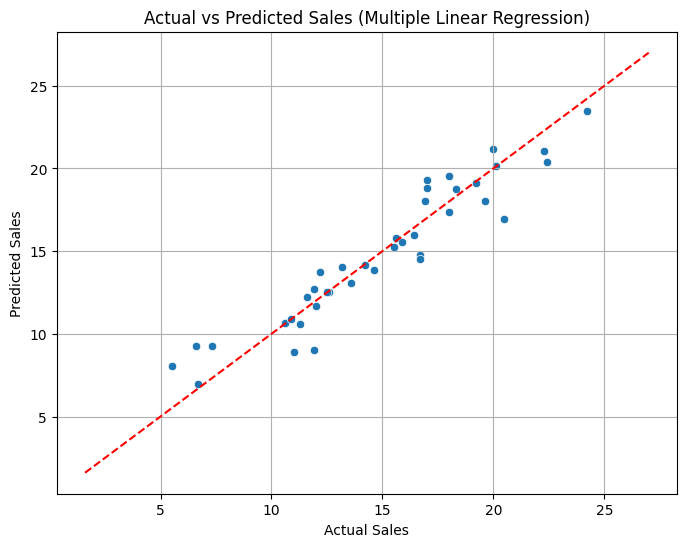

In [12]:
plt.figure(figsize=(8, 6))
sns.scatterplot(x=y_test, y=y_pred)
plt.xlabel("Actual Sales")
plt.ylabel("Predicted Sales")
plt.title("Actual vs Predicted Sales (Multiple Linear Regression)")
plt.plot([y.min(), y.max()], [y.min(), y.max()], 'r--')
plt.grid()
plt.show()

# **Predict Sales**

In [19]:
new_data = pd.DataFrame({'TV': [200], 'Radio': [40], 'Newspaper': [50]})
predicted_sales = model.predict(new_data)
print(f"Predicted Sales: {predicted_sales[0]:.2f} units")

Predicted Sales: 19.82 units


# **Model Performance**

In [14]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
X_train_s, X_test_s, y_train_s, y_test_s = train_test_split(X_scaled, y, test_size=0.2, random_state=42)

In [15]:
model_scaled = LinearRegression()
model_scaled.fit(X_train_s, y_train_s)
y_pred_s = model_scaled.predict(X_test_s)

In [16]:
print("Without Normalization:")
print(f"R^2 Score: {r2_score(y_test, y_pred):.3f}")
print("With Normalization:")
print(f"R^2 Score: {r2_score(y_test_s, y_pred_s):.3f}")

Without Normalization:
R^2 Score: 0.899
With Normalization:
R^2 Score: 0.899


# **Only Radio and Newspaper to Predict Sales**

In [17]:
X_radio_newspaper = df[['Radio', 'Newspaper']]
X_train_rn, X_test_rn, y_train_rn, y_test_rn = train_test_split(X_radio_newspaper, y, test_size=0.2, random_state=42)

model_rn = LinearRegression()
model_rn.fit(X_train_rn, y_train_rn)
y_pred_rn = model_rn.predict(X_test_rn)

print("Model using only Radio and Newspaper:")
print(f"R^2 Score: {r2_score(y_test_rn, y_pred_rn):.3f}")

Model using only Radio and Newspaper:
R^2 Score: -0.052
